In [1]:
import pandas as pd
import numpy as np

In [2]:
columns = [
    "age",
    "sex",
    "cp",
    "trestbps",
    "chol",
    "fbs",
    "restecg",
    "thalach",
    "exang",
    "oldpeak",
    "slope",
    "ca",
    "thal",
    "target"
]

df = pd.read_csv(
    "processed.cleveland.data",
    names=columns
)

print(df.head())

    age  sex   cp  trestbps   chol  fbs  restecg  thalach  exang  oldpeak  \
0  63.0  1.0  1.0     145.0  233.0  1.0      2.0    150.0    0.0      2.3   
1  67.0  1.0  4.0     160.0  286.0  0.0      2.0    108.0    1.0      1.5   
2  67.0  1.0  4.0     120.0  229.0  0.0      2.0    129.0    1.0      2.6   
3  37.0  1.0  3.0     130.0  250.0  0.0      0.0    187.0    0.0      3.5   
4  41.0  0.0  2.0     130.0  204.0  0.0      2.0    172.0    0.0      1.4   

   slope   ca thal  target  
0    3.0  0.0  6.0       0  
1    2.0  3.0  3.0       2  
2    2.0  2.0  7.0       1  
3    3.0  0.0  3.0       0  
4    1.0  0.0  3.0       0  


In [3]:
df.size

4242

In [4]:
df['target'] = (df['target'] >= 1).astype(int)

In [5]:
df.head(5)

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,1
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


In [6]:
df['ca']

0      0.0
1      3.0
2      2.0
3      0.0
4      0.0
      ... 
298    0.0
299    2.0
300    1.0
301    1.0
302      ?
Name: ca, Length: 303, dtype: object

In [7]:
df['ca'] = df['ca'].replace('?', np.nan)
df['ca'] = pd.to_numeric(df['ca'])
df['ca'] = df['ca'].fillna(df['ca'].median())

In [8]:
df['ca']

0      0.0
1      3.0
2      2.0
3      0.0
4      0.0
      ... 
298    0.0
299    2.0
300    1.0
301    1.0
302    0.0
Name: ca, Length: 303, dtype: float64

In [9]:
print((df['thal']=='?').sum())

2


In [10]:
df['thal']

0      6.0
1      3.0
2      7.0
3      3.0
4      3.0
      ... 
298    7.0
299    7.0
300    7.0
301    3.0
302    3.0
Name: thal, Length: 303, dtype: object

In [11]:
df['thal'] = df['thal'].replace('?', np.nan)

df['thal'] = df['thal'].fillna(df['thal'].mode()[0])

In [12]:
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,1
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


In [13]:
df.shape

(303, 14)

In [14]:
df['fbs']

0      1.0
1      0.0
2      0.0
3      0.0
4      0.0
      ... 
298    0.0
299    1.0
300    0.0
301    0.0
302    0.0
Name: fbs, Length: 303, dtype: float64

In [15]:
df.shape

(303, 14)

In [16]:
df.describe()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,target
count,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000
mean,54.438944,0.679868,3.158416,131.689769,246.693069,0.148515,0.990099,149.607261,0.326733,1.039604,1.600660,0.663366,0.458746
std,9.038662,0.467299,0.960126,17.599748,51.776918,0.356198,0.994971,22.875003,0.469794,1.161075,0.616226,0.934375,0.499120
min,29.000000,0.000000,1.000000,94.000000,126.000000,0.000000,0.000000,71.000000,0.000000,0.000000,1.000000,0.000000,0.000000
25%,48.000000,0.000000,3.000000,120.000000,211.000000,0.000000,0.000000,133.500000,0.000000,0.000000,1.000000,0.000000,0.000000
50%,56.000000,1.000000,3.000000,130.000000,241.000000,0.000000,1.000000,153.000000,0.000000,0.800000,2.000000,0.000000,0.000000
75%,61.000000,1.000000,4.000000,140.000000,275.000000,0.000000,2.000000,166.000000,1.000000,1.600000,2.000000,1.000000,1.000000
max,77.000000,1.000000,4.000000,200.000000,564.000000,1.000000,2.000000,202.000000,1.000000,6.200000,3.000000,3.000000,1.000000


In [17]:
df['sex'].value_counts()

sex
1.0    206
0.0     97
Name: count, dtype: int64

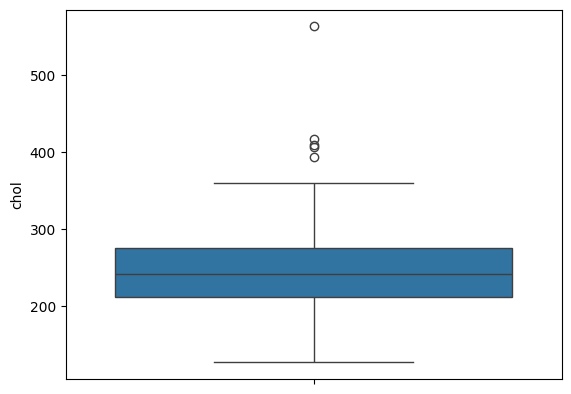

In [18]:
import seaborn as sns
import matplotlib.pyplot as plt
sns.boxplot(df['chol'])
plt.show()

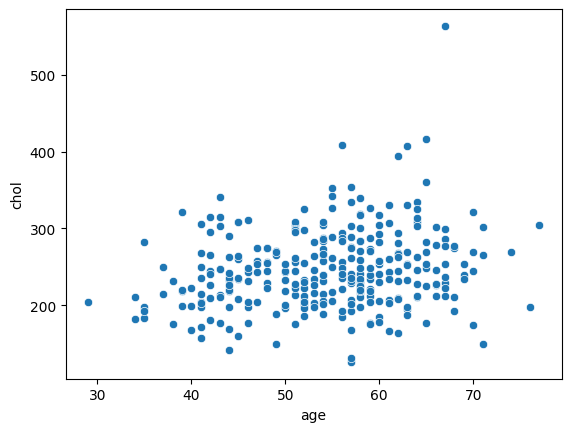

In [19]:
sns.scatterplot(x='age', y='chol', data=df)
plt.show()

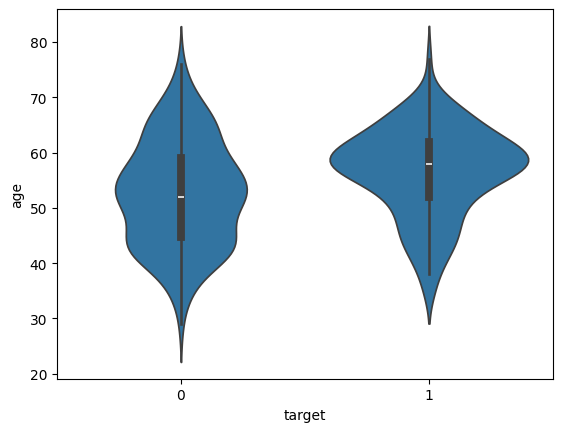

In [20]:
sns.violinplot(x='target', y='age', data=df)
plt.show()

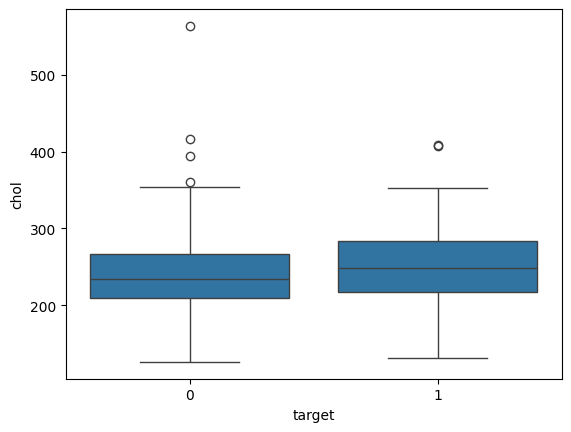

In [21]:
sns.boxplot(x='target', y='chol', data=df)
plt.show()

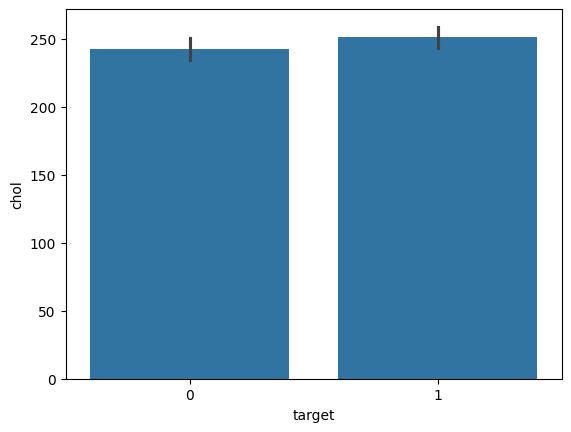

In [22]:
sns.barplot(x='target', y='chol', data=df)
plt.show()

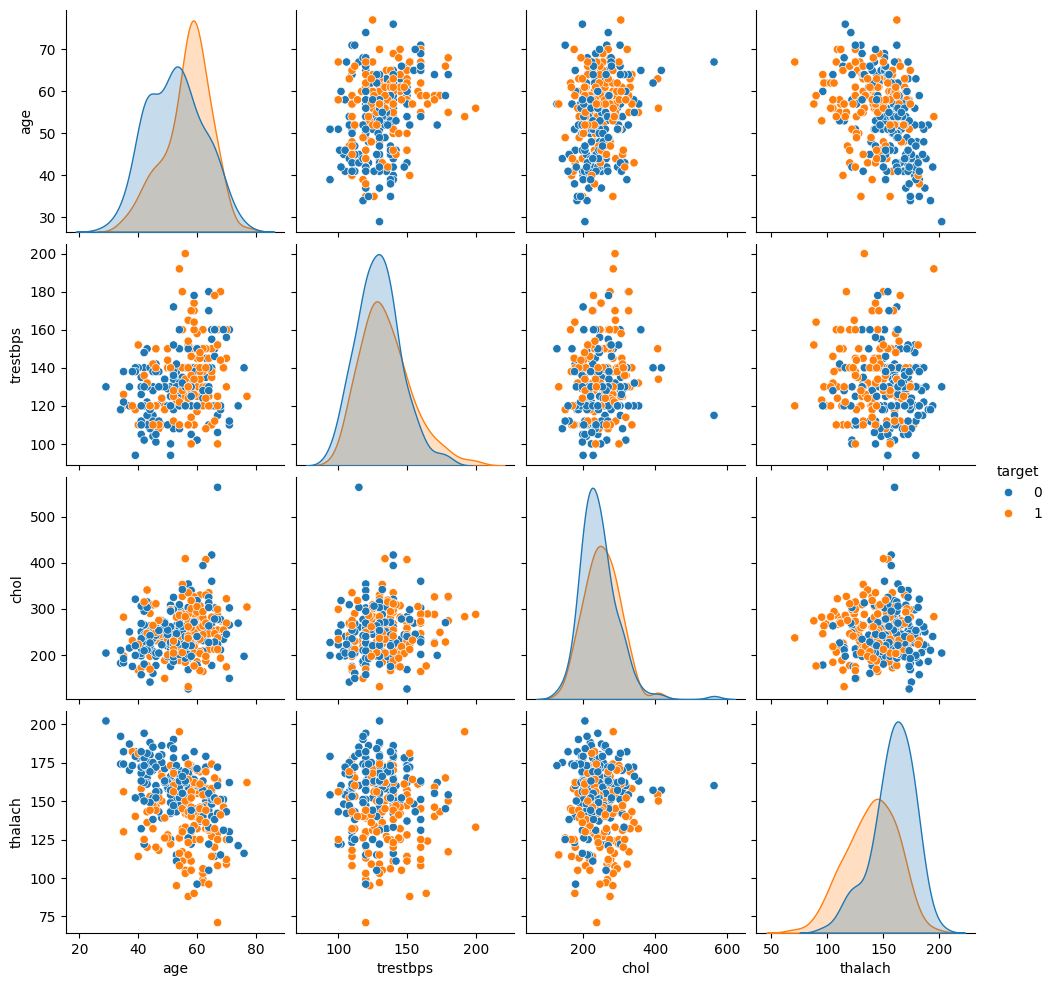

In [23]:
sns.pairplot(
    df[['age', 'trestbps', 'chol', 'thalach', 'target']],
    hue='target'
)

plt.show()

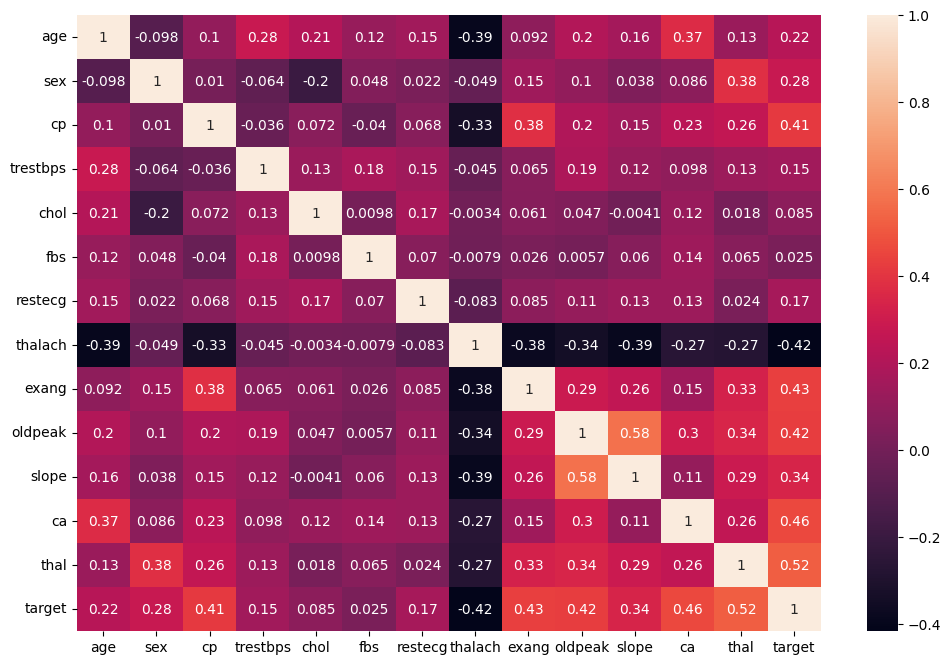

In [24]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    df.corr(),
    annot=True
)

plt.show()

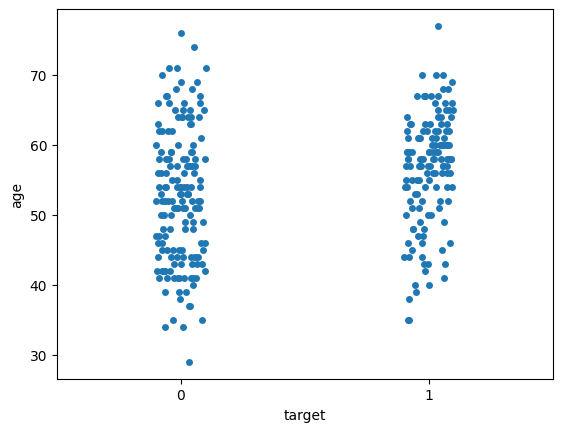

In [25]:
sns.stripplot(
    x='target',
    y='age',
    data=df
)
plt.show()

<Axes: >

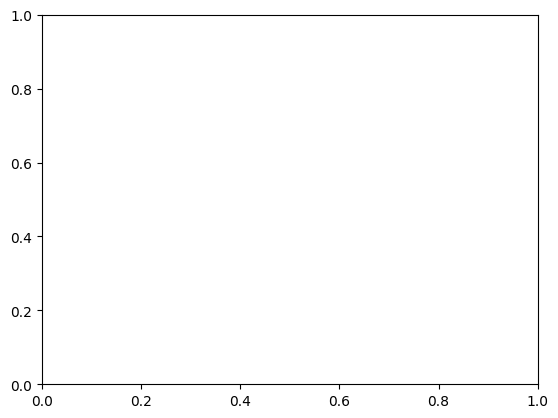

In [26]:
sns.countplot()

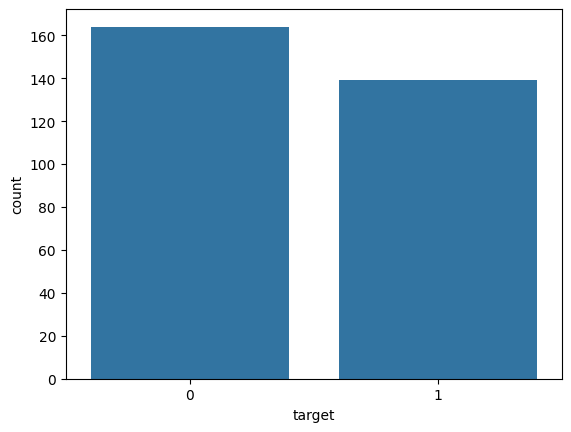

In [27]:
sns.countplot(x='target', data=df)
plt.show()

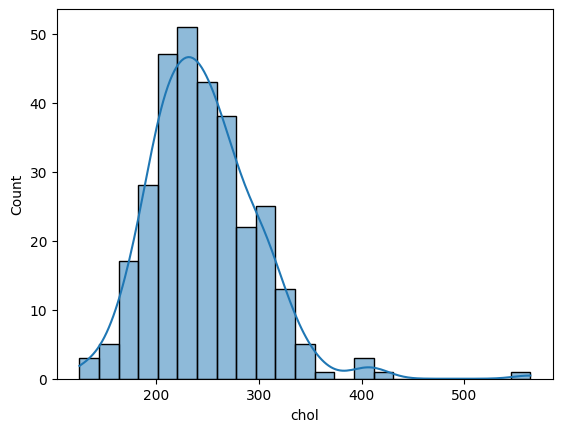

In [28]:
sns.histplot(df['chol'], kde=True)
plt.show()

In [29]:
X=df.drop('target', axis=1)
y=df['target']

In [30]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(
    X,y,test_size=0.2,random_state=42
)


In [31]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [32]:
from sklearn.svm import SVC
# model=SVC()
model = SVC(kernel='poly',degree=3)

model.fit(X_train,y_train)

,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'poly'
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


In [33]:
y_pred=model.predict(X_test)
from sklearn.metrics import accuracy_score,precision_score

In [34]:
print(accuracy_score(y_test,y_pred))

0.9180327868852459


In [35]:
from sklearn.metrics import classification_report
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.88      0.97      0.92        29
           1       0.97      0.88      0.92        32

    accuracy                           0.92        61
   macro avg       0.92      0.92      0.92        61
weighted avg       0.92      0.92      0.92        61



In [36]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

print(cm)

[[28  1]
 [ 4 28]]


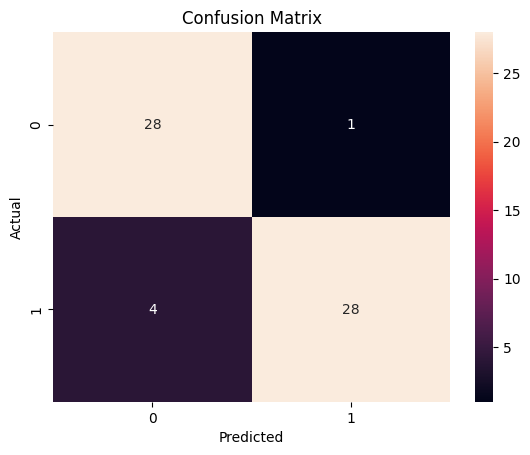

In [37]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.heatmap(cm, annot=True, fmt='d')

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")

plt.show()

In [ ]:
from sklearn.model_selection import GridSearchCV
from sklearn.svm import SVC

params = {
    'kernel': ['linear', 'rbf', 'poly', 'sigmoid'],
    'C': [0.1, 1, 10, 100],
    'gamma': ['scale', 'auto', 0.01, 0.1, 1]
}

grid = GridSearchCV(
    SVC(),
    params,
    cv=5,
    scoring='accuracy'
)

grid.fit(X_train, y_train)

print(grid.best_params_)
print(grid.best_score_)

{'C': 0.1, 'gamma': 'scale', 'kernel': 'sigmoid'}
0.8388605442176871


In [39]:
best_model = grid.best_estimator_

y_pred = best_model.predict(X_test)

In [40]:
print(accuracy_score(y_pred,y_test))
print(confusion_matrix(y_pred,y_test))

0.8852459016393442
[[27  5]
 [ 2 27]]


In [41]:
params = [
    {
        'kernel': ['linear'],
        'C': [0.01, 0.1, 1, 10, 100]
    },
    {
        'kernel': ['rbf'],
        'C': [0.01, 0.1, 1, 10, 100],
        'gamma': ['scale', 'auto', 0.001, 0.01, 0.1, 1]
    },
    {
        'kernel': ['poly'],
        'C': [0.1, 1, 10],
        'gamma': ['scale', 'auto', 0.01, 0.1],
        'degree': [2, 3, 4]
    },
    {
        'kernel': ['sigmoid'],
        'C': [0.01, 0.1, 1, 10, 100],
        'gamma': ['scale', 'auto', 0.001, 0.01, 0.1, 1]
    }
]

In [42]:
grid = GridSearchCV(
    SVC(),
    params,
    cv=5,
    scoring='accuracy'
)

grid.fit(X_train, y_train)

print("Best parameters:", grid.best_params_)
print("Best CV score:", grid.best_score_)

Best parameters: {'C': 0.1, 'gamma': 'scale', 'kernel': 'sigmoid'}
Best CV score: 0.8388605442176871


In [43]:
best_model = grid.best_estimator_

y_pred = best_model.predict(X_test)

print("Test Accuracy:", accuracy_score(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))

Test Accuracy: 0.8852459016393442
[[27  2]
 [ 5 27]]


In [44]:
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Parameters for Polynomial SVM
params = {
    'kernel': ['poly'],
    'C': [0.1, 1, 10, 100],
    'degree': [2, 3, 4],
    'gamma': ['scale', 'auto', 0.01, 0.1, 1]
}

# GridSearchCV
grid = GridSearchCV(
    SVC(),
    params,
    cv=5,
    scoring='accuracy'
)

# Train
grid.fit(X_train, y_train)

# Best parameters
print("Best Parameters:", grid.best_params_)

# Best cross-validation score
print("Best CV Score:", grid.best_score_)

# Get best model
best_model = grid.best_estimator_

# Prediction
y_pred = best_model.predict(X_test)

# Test accuracy
print("Test Accuracy:", accuracy_score(y_test, y_pred))

# Classification report
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# Confusion matrix
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Best Parameters: {'C': 1, 'degree': 3, 'gamma': 0.1, 'kernel': 'poly'}
Best CV Score: 0.8264455782312925
Test Accuracy: 0.9016393442622951

Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.90      0.90        29
           1       0.91      0.91      0.91        32

    accuracy                           0.90        61
   macro avg       0.90      0.90      0.90        61
weighted avg       0.90      0.90      0.90        61


Confusion Matrix:
[[26  3]
 [ 3 29]]


In [45]:
print("Accuracy:", accuracy_score(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Accuracy: 0.9016393442622951

Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.90      0.90        29
           1       0.91      0.91      0.91        32

    accuracy                           0.90        61
   macro avg       0.90      0.90      0.90        61
weighted avg       0.90      0.90      0.90        61


Confusion Matrix:
[[26  3]
 [ 3 29]]


In [46]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('svm', SVC())
])

In [47]:
params_poly = {
    'svm__kernel': ['poly'],
    'svm__C': [0.01, 0.1, 1, 10, 100],
    'svm__degree': [2, 3, 4, 5],
    'svm__gamma': ['scale', 'auto', 0.001, 0.01, 0.1, 1]
}

grid_poly = GridSearchCV(
    pipe,
    params_poly,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

grid_poly.fit(X_train, y_train)

print("Best parameters:", grid_poly.best_params_)
print("Best CV accuracy:", grid_poly.best_score_)

Best parameters: {'svm__C': 1, 'svm__degree': 3, 'svm__gamma': 0.1, 'svm__kernel': 'poly'}
Best CV accuracy: 0.8305272108843539


In [48]:
best_poly = grid_poly.best_estimator_

y_pred_poly = best_poly.predict(X_test)

print("Test Accuracy:",
      accuracy_score(y_test, y_pred_poly))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_poly))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_poly))

Test Accuracy: 0.9016393442622951

Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.90      0.90        29
           1       0.91      0.91      0.91        32

    accuracy                           0.90        61
   macro avg       0.90      0.90      0.90        61
weighted avg       0.90      0.90      0.90        61


Confusion Matrix:
[[26  3]
 [ 3 29]]


In [49]:
from sklearn.model_selection import cross_val_score, StratifiedKFold

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scores = cross_val_score(
    best_poly,
    X,
    y,
    cv=cv,
    scoring='accuracy'
)

print("CV Scores:", scores)
print("Mean CV Accuracy:", scores.mean())
print("Std:", scores.std())

CV Scores: [0.86885246 0.83606557 0.78688525 0.8        0.83333333]
Mean CV Accuracy: 0.8250273224043715
Std: 0.028957417966761823


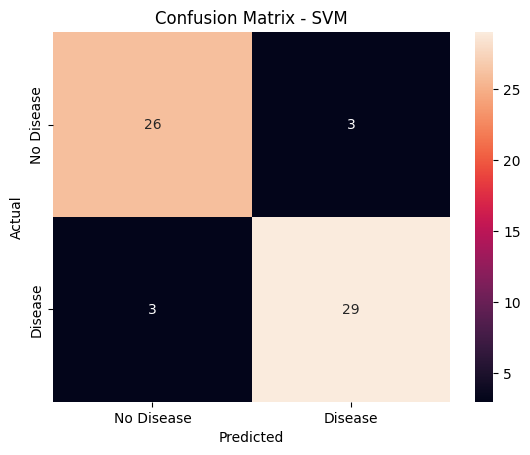

In [50]:
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred_poly)

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    xticklabels=['No Disease', 'Disease'],
    yticklabels=['No Disease', 'Disease']
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - SVM")
plt.show()

In [51]:
import pickle

with open("heart_disease_svm.pkl", "wb") as file:
    pickle.dump(best_poly, file)

print("Model saved successfully!")

Model saved successfully!
